
# Customer Churn Analysis

## 1. Project Overview

Customer churn occurs when a customer stops using a company's products or services. Understanding churn helps businesses identify customer retention challenges and develop strategies to improve customer satisfaction and loyalty.

This project analyzes customer data from a telecommunications company to explore customer characteristics, service usage, billing patterns, and churn behavior. The goal is to identify patterns associated with customer churn and translate the findings into actionable business insights.

The project combines Python-based exploratory data analysis, SQL querying, and Power BI visualization to support a comprehensive analysis of customer churn.

## 2. Project Objectives

- Understand the structure and quality of the dataset.
- Identify missing values, duplicate records, and data type issues.
- Clean and prepare the data for analysis.
- Explore customer characteristics, service usage, and billing patterns.
- Calculate and compare customer churn rates.
- Investigate factors associated with customer churn.
- Develop actionable business recommendations to support customer retention.
- Present key insights through an interactive Power BI dashboard.

## 3. Tools and Technologies

- **Python:** Data exploration and cleaning.
- **Pandas:** Data manipulation and analysis.
- **Matplotlib and Seaborn:** Data visualization.
- **SQL:** Data querying, aggregation, and analysis.
- **Power BI:** Interactive dashboard development and business reporting.
- **Jupyter Notebook:** Analysis documentation and workflow.

## 4. Dataset Overview

The dataset contains customer-level information for a telecommunications company, including demographic attributes, subscribed services, contract types, billing information, tenure, and churn status.

The target column is `Churn`, which indicates whether a customer has left the company.

The initial dataset contains **7,043 rows and 21 columns**.

## 5. Analytical Workflow

1. Load the dataset and inspect its structure.
2. Assess data quality and investigate missing values and duplicates.
3. Clean and prepare the data for analysis.
4. Perform exploratory data analysis (EDA) using Python.
5. Conduct SQL-based analysis to investigate customer churn patterns.
6. Develop an interactive Power BI dashboard to visualize key metrics and findings.
7. Consolidate the results, identify business insights, and develop customer retention recommendations.
8. Document the project and prepare the final deliverables for publication.


In [1]:
import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



## 6. Initial Data Inspection

The dataset was successfully loaded into a Pandas DataFrame.

The initial inspection confirms that the dataset contains **7,043 records and 21 columns**. Each record represents a customer, while the columns describe customer demographics, service subscriptions, contract information, billing details, and churn status.

The `Churn` column will be used to distinguish customers who left the company from those who remained.

### Next Step

Inspect column names, data types, and non-null counts to identify potential data quality issues before starting the cleaning process.


In [2]:
# Check column names, data types, and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen


## 7. Dataset Structure and Data Types

The dataset contains 7,043 rows and 21 columns. The initial inspection shows that all columns report 7,043 non-null values.

Most columns contain categorical customer information, while `tenure`, `SeniorCitizen`, and `MonthlyCharges` are stored as numeric variables.

### Data Quality Observation

The `TotalCharges` column is currently stored as a string (`str`) rather than a numeric variable. This may prevent accurate numerical calculations and requires further investigation.

Although the initial inspection reports no null values, additional checks are needed to identify blank strings, whitespace-only values, and other potential data quality issues.

### Next Step

Investigate the `TotalCharges` column and verify whether it contains blank or non-numeric values before converting it to a numeric data type.


In [3]:

# Inspect TotalCharges for blank and non-numeric values

total_charges_clean = df["TotalCharges"].str.strip()

blank_values = total_charges_clean.eq("").sum()

numeric_values = pd.to_numeric(
    total_charges_clean,
    errors="coerce"
)

invalid_values = numeric_values.isna().sum()

print("Blank or whitespace-only values:", blank_values)
print("Missing or non-numeric values after conversion:", invalid_values)
print("Original TotalCharges data type:", df["TotalCharges"].dtype)


Blank or whitespace-only values: 11
Missing or non-numeric values after conversion: 11
Original TotalCharges data type: str



## 8. Data Quality Assessment: TotalCharges

The initial inspection identified a data type issue in the `TotalCharges` column.

Although the column contains 7,043 non-null entries according to `df.info()`, further investigation revealed 11 blank or whitespace-only values.

After trimming whitespace and attempting numeric conversion, the same 11 values were identified as missing or non-numeric.

### Key Finding

- Total records: 7,043
- Blank `TotalCharges` values: 11
- Percentage of records with blank values: approximately 0.16%

These values must be handled before performing numerical analysis on `TotalCharges`.

### Next Step

Investigate the affected customer records and determine an appropriate treatment for the missing values.


In [4]:

# Display customer records with blank TotalCharges

blank_mask = df["TotalCharges"].str.strip().eq("")

display(
    df.loc[
        blank_mask,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



## 9. Investigation of Missing TotalCharges

The 11 records with blank `TotalCharges` values all have a tenure of zero months and a churn status of `No`.

This pattern is consistent with customers who may have only recently started their service. However, the underlying reason for the missing charges cannot be confirmed from these records alone.

### Data Cleaning Decision

- Retain all 11 customer records to preserve useful customer and service information.
- Convert `TotalCharges` to a numeric data type.
- Represent blank or invalid entries as missing values (`NaN`).
- Exclude missing `TotalCharges` values from calculations that require valid numeric amounts.

This approach avoids unnecessary record deletion and prevents missing values from being treated as actual charges.


In [5]:

# Convert TotalCharges to a numeric data type

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges values:", df["TotalCharges"].isna().sum())


TotalCharges data type: float64
Missing TotalCharges values: 11



## 10. Duplicate Records and Missing Value Assessment

After converting `TotalCharges` to a numeric data type, the next step is to assess the dataset for duplicate records and missing values across all columns.

This check helps determine whether additional data cleaning is required before exploratory data analysis.

The assessment will examine:
- Duplicate rows across the dataset.
- Missing values in each column.
- The percentage of missing values per column.


In [6]:

# Check for duplicate rows
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

# Check missing values by column
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage (%)": (df.isna().mean() * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Values"] > 0]
    .sort_values("Missing Values", ascending=False)
)


Duplicate rows: 0


,Missing Values,Missing Percentage (%)
TotalCharges,11,0.16



## 11. Data Quality Assessment Results

The data quality assessment produced the following findings:

- **Duplicate rows:** No fully duplicated records were identified.
- **Missing values:** 11 missing values were found in `TotalCharges`.
- **Missing value rate:** The affected records represent approximately 0.16% of the dataset.
- **Record retention:** All 7,043 customer records have been retained.

### Conclusion

No duplicate-row removal is required. The 11 missing `TotalCharges` values will remain as missing values rather than being replaced with arbitrary amounts or causing entire customer records to be deleted.

The dataset can now proceed to exploratory data analysis, while numerical analyses involving `TotalCharges` will account for these missing values.



## 12. Exploratory Data Analysis (EDA)

### 12.1 Customer Churn Distribution

The first stage of exploratory data analysis examines the distribution of the target variable, `Churn`.

Understanding how many customers have left the company compared with those who remain provides a baseline for the subsequent analysis.

The analysis will calculate the customer count and percentage for each churn category.


In [14]:
# Calculate customer churn counts and percentages

churn_summary = (
    df["Churn"]
    .value_counts()
    .rename_axis("Churn Status")
    .reset_index(name="Customer Count")
)

churn_summary["Percentage (%)"] = (
    churn_summary["Customer Count"] / len(df) * 100
).round(2)

display(churn_summary)

,Churn Status,Customer Count,Percentage (%)
0,No,5174,73.46
1,Yes,1869,26.54


### Findings

The dataset contains 7,043 customers. Of these, 5,174 customers (73.46%) remained with the company, while 1,869 customers (26.54%) churned.

The overall customer churn rate is **26.54%**.

This means that approximately one in four customers in the dataset has left the company. Customer churn therefore represents an important area for further investigation.

The next stage will examine how churn varies across customer tenure, contract types, service subscriptions, and billing characteristics. These comparisons can help identify patterns associated with customer attrition, although they do not by themselves establish causation.

### 12.2 Customer Tenure and Churn

Customer tenure represents the number of months a customer has stayed with the company.

This analysis compares the tenure of customers who churned with those who remained. It will help identify whether customer retention patterns differ according to the length of the customer relationship.

The analysis will calculate the average and median tenure for each churn category and visualize the comparison using a box plot.

In [15]:
# Compare customer tenure by churn status

tenure_summary = (
    df.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

tenure_summary.columns = [
    "Churn Status",
    "Customer Count",
    "Average Tenure (Months)",
    "Median Tenure (Months)"
]

tenure_summary["Average Tenure (Months)"] = (
    tenure_summary["Average Tenure (Months)"].round(2)
)

display(tenure_summary)

,Churn Status,Customer Count,Average Tenure (Months),Median Tenure (Months)
0,No,5174,37.57,38.0
1,Yes,1869,17.98,10.0


#### Findings

The tenure analysis reveals a clear difference between customers who churned and those who remained with the company.

- **Retained customers:** 5,174 customers, with an average tenure of 37.57 months and a median tenure of 38 months.
- **Churned customers:** 1,869 customers, with an average tenure of 17.98 months and a median tenure of 10 months.

Customers who churned generally had shorter relationships with the company than customers who remained. The median tenure of churned customers was particularly low, suggesting that many churned customers left relatively early in their customer journey.

These results indicate that early customer retention deserves further investigation. However, tenure alone does not establish why customers leave.

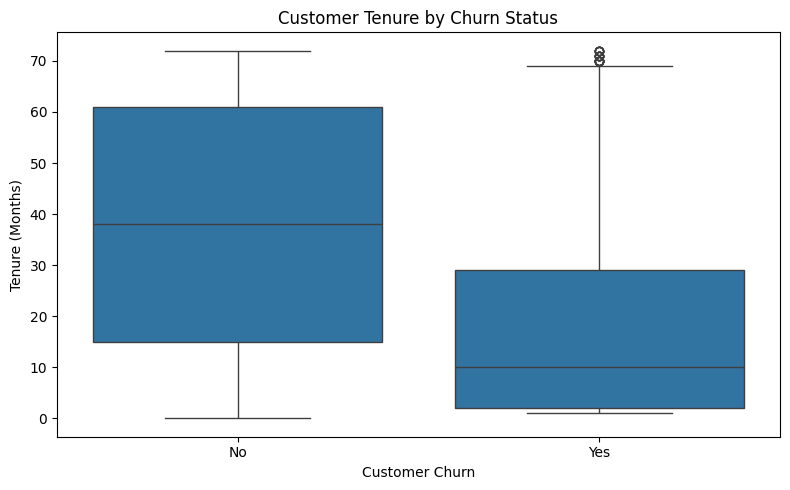

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    order=["No", "Yes"]
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

#### Box Plot Findings

The box plot highlights a clear difference in customer tenure between customers who remained with the company and those who churned.

Customers who stayed with the company had a median tenure of **38 months**, compared with only **10 months** for customers who churned. This indicates that churned customers generally had shorter relationships with the company.

The distribution for churned customers is concentrated at lower tenure values, although some customers left after several years of service. The overlap between the two distributions also shows that tenure alone cannot fully explain or predict customer churn.

These findings suggest that improving the customer experience during the early stages of the customer relationship may be an important retention priority. Further analysis is needed to identify the specific tenure periods associated with higher churn rates.

### 12.3 Customer Churn by Contract Type

This analysis examines customer churn across different contract types: month-to-month, one-year, and two-year contracts.

The objective is to compare churn rates across contract categories and identify contract types that may be associated with higher customer attrition.

Churn rates will be calculated as the percentage of customers within each contract category who have left the company.

In [17]:
# Calculate churn rates by contract type

contract_churn = (
    df.groupby("Contract")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

contract_churn["Churn Rate (%)"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Customer_Count"] * 100
).round(2)

contract_churn = contract_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

display(contract_churn)

,Contract,Customer_Count,Churned_Customers,Churn Rate (%)
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


#### Findings

The analysis reveals substantial differences in customer churn rates across contract types.

- **Month-to-month contracts:** 3,875 customers, of whom 1,655 churned, resulting in a churn rate of **42.71%**.
- **One-year contracts:** 1,473 customers, of whom 166 churned, resulting in a churn rate of **11.27%**.
- **Two-year contracts:** 1,695 customers, of whom 48 churned, resulting in a churn rate of **2.83%**.

Customers with month-to-month contracts had the highest churn rate, while customers with two-year contracts had the lowest. The churn rate for month-to-month customers was approximately 15 times that of two-year contract customers.

These findings show a strong association between contract type and customer churn. However, the analysis does not establish that contract duration itself causes customers to stay or leave. Other factors, such as pricing, service quality, and customer satisfaction, may also influence churn.

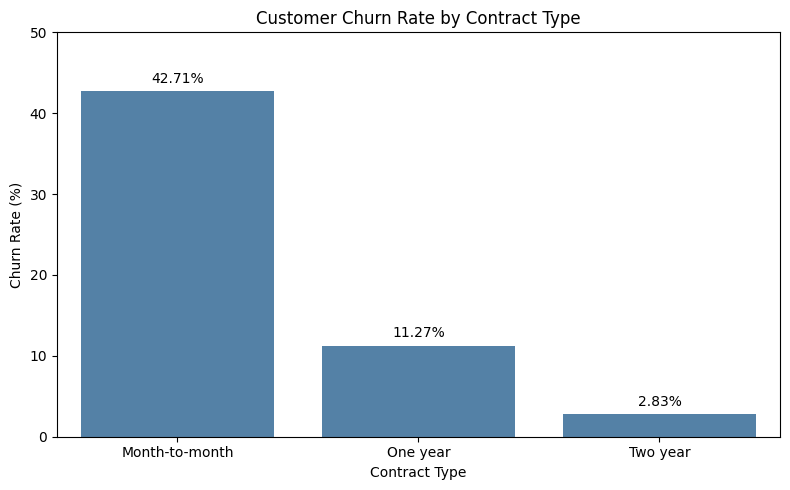

In [18]:
# Visualize churn rate by contract type

plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_churn,
    x="Contract",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(contract_churn["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The analysis reveals a strong association between contract type and customer churn.

Customers with month-to-month contracts had the highest churn rate at **42.71%**, compared with **11.27%** for one-year contracts and **2.83%** for two-year contracts. The churn rate for month-to-month customers was approximately 15 times higher than that of customers with two-year contracts.

This pattern indicates that customers on month-to-month contracts represent an important segment for further retention analysis. The company could investigate their reasons for leaving and evaluate targeted retention strategies. However, these results show an association between contract type and churn and do not establish that contract duration directly causes customers to leave or stay.

### 12.4 Customer Churn by Tenure Group

This analysis examines customer churn across different tenure groups to identify how churn rates vary throughout the customer lifecycle.

Customer tenure will be grouped into four categories: 0–12 months, 13–24 months, 25–48 months, and 49–72 months.

For each group, the analysis will calculate the total number of customers, the number of customers who churned, and the churn rate.

This comparison will help identify tenure periods that may require closer attention from customer retention teams.

In [19]:
# Group customers by tenure and calculate churn rates

tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = [
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]

df["Tenure Group"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

tenure_churn = (
    df.groupby("Tenure Group", observed=False)
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

tenure_churn["Churn Rate (%)"] = (
    tenure_churn["Churned_Customers"]
    / tenure_churn["Customer_Count"] * 100
).round(2)

display(tenure_churn)

,Tenure Group,Customer_Count,Churned_Customers,Churn Rate (%)
0,0-12 months,2186,1037,47.44
1,13-24 months,1024,294,28.71
2,25-48 months,1594,325,20.39
3,49-72 months,2239,213,9.51


#### Findings

The analysis reveals a clear relationship between customer tenure and churn rates.

- **0–12 months:** 2,186 customers, with a churn rate of **47.44%**.
- **13–24 months:** 1,024 customers, with a churn rate of **28.71%**.
- **25–48 months:** 1,594 customers, with a churn rate of **20.39%**.
- **49–72 months:** 2,239 customers, with a churn rate of **9.51%**.

The highest churn rate occurs among customers in their first 12 months, while customers with 49–72 months of tenure have the lowest rate. The churn rate decreases progressively across the four tenure groups.

These findings suggest that the early customer lifecycle deserves particular attention in retention efforts. However, the results show an association between tenure and churn and do not establish that tenure itself causes customers to stay or leave.

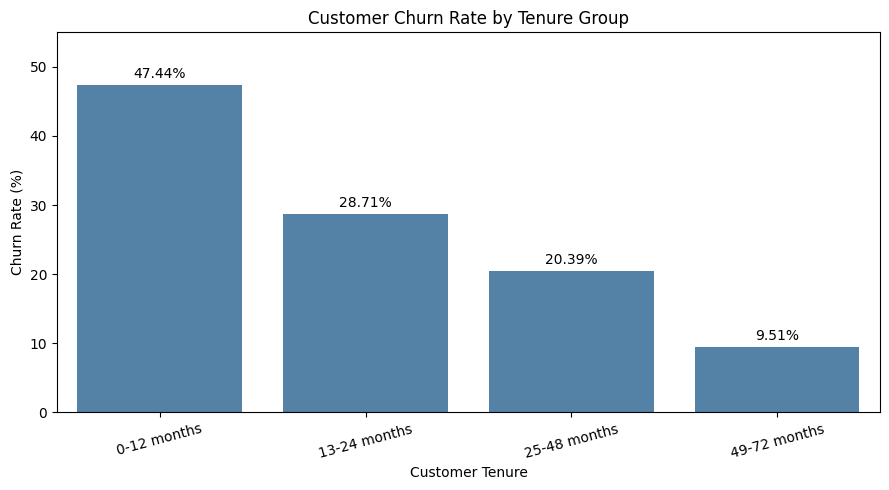

In [20]:
# Visualize churn rate by tenure group

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_churn,
    x="Tenure Group",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)
plt.xticks(rotation=15)

for i, value in enumerate(tenure_churn["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The analysis reveals a consistent decline in customer churn rates across the four tenure groups.

Customers with 0–12 months of tenure have the highest churn rate at **47.44%**. The rate decreases to **28.71%** for customers with 13–24 months of tenure, **20.39%** for those with 25–48 months, and **9.51%** for customers with 49–72 months of tenure.

This pattern indicates that newer customers are more likely to churn than customers who have maintained a longer relationship with the company. The first 12 months therefore represent an important period for customer retention efforts.

The business could investigate early customer experiences and introduce targeted onboarding and follow-up initiatives. These findings show an association between tenure and churn, but they do not establish causation.

### 12.5 Customer Churn by Monthly Charges

This analysis investigates how customer churn rates vary across monthly billing levels.

Monthly charges will be divided into three groups: low, medium, and high. The analysis will calculate the number of customers and the churn rate within each group to identify potential patterns between monthly charges and customer attrition.

The results may help identify billing segments that require further investigation, although differences in churn rates do not establish that monthly charges cause customers to leave.

In [21]:
# Group customers by monthly charges and calculate churn rates

df["Monthly Charges Group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

charges_churn = (
    df.groupby("Monthly Charges Group", observed=False)
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

charges_churn["Churn Rate (%)"] = (
    charges_churn["Churned_Customers"]
    / charges_churn["Customer_Count"] * 100
).round(2)

display(charges_churn)

,Monthly Charges Group,Customer_Count,Churned_Customers,Churn Rate (%)
0,Low,1735,189,10.89
1,Medium,1725,413,23.94
2,High,3583,1267,35.36


#### Findings

The analysis shows a clear difference in customer churn rates across monthly charge groups.

- **Low monthly charges:** 1,735 customers, with a churn rate of **10.89%**.
- **Medium monthly charges:** 1,725 customers, with a churn rate of **23.94%**.
- **High monthly charges:** 3,583 customers, with a churn rate of **35.36%**.

Customers in the high monthly charge group have the highest churn rate, while those in the low charge group have the lowest. The churn rate increases across all three billing groups, reaching more than three times the rate observed in the low charge group.

This pattern suggests that customers with higher monthly bills may represent an important segment for further investigation. The company could examine whether pricing, service bundles, contract types, or perceived value are associated with this pattern. However, these results show an association and do not establish that higher monthly charges cause customer churn.

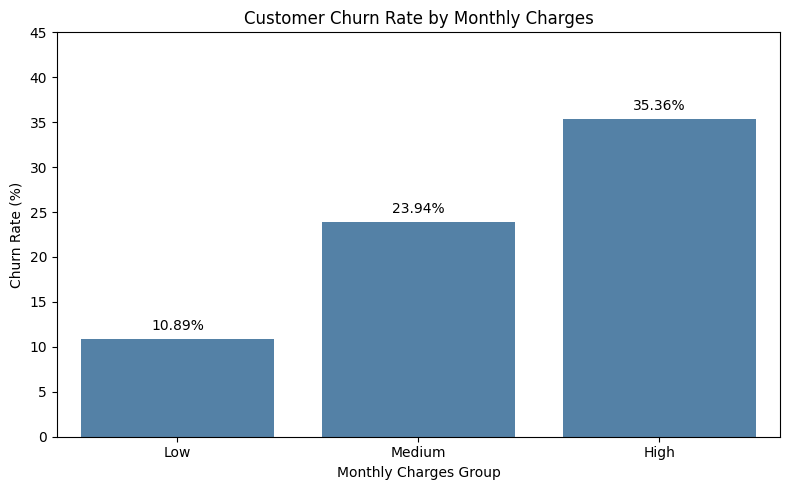

In [22]:
# Visualize churn rate by monthly charges group

plt.figure(figsize=(8, 5))

sns.barplot(
    data=charges_churn,
    x="Monthly Charges Group",
    y="Churn Rate (%)",
    order=["Low", "Medium", "High"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 45)

for i, value in enumerate(
    charges_churn.set_index("Monthly Charges Group")
    .loc[["Low", "Medium", "High"], "Churn Rate (%)"]
):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart shows a clear increase in customer churn rates across the three monthly charge groups.

Customers in the **Low** monthly charges group have a churn rate of **10.89%**, compared with **23.94%** for the **Medium** group and **35.36%** for the **High** group.

The **High** monthly charges group has the highest churn rate, while the **Low** group has the lowest. This pattern suggests that customers with higher monthly bills may require further investigation to understand their retention challenges.

The company should examine whether contract type, customer tenure, and subscribed services are associated with this pattern. However, these results show an association between monthly charges and churn and do not establish that higher charges cause customers to leave.

### 12.6 Customer Churn by Internet Service

This analysis examines customer churn across different internet service categories: DSL, Fiber optic, and customers without internet service.

The objective is to compare the number of customers and churn rates across these categories to identify potential differences in customer retention.

Churn rates will be calculated as the percentage of customers within each internet service category who have left the company. These results may help identify service categories that require further investigation, although they do not establish that internet service type causes customer churn.

In [23]:
# Calculate churn rates by internet service type

internet_churn = (
    df.groupby("InternetService")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

internet_churn["Churn Rate (%)"] = (
    internet_churn["Churned_Customers"]
    / internet_churn["Customer_Count"] * 100
).round(2)

internet_churn = internet_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

display(internet_churn)

,InternetService,Customer_Count,Churned_Customers,Churn Rate (%)
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40


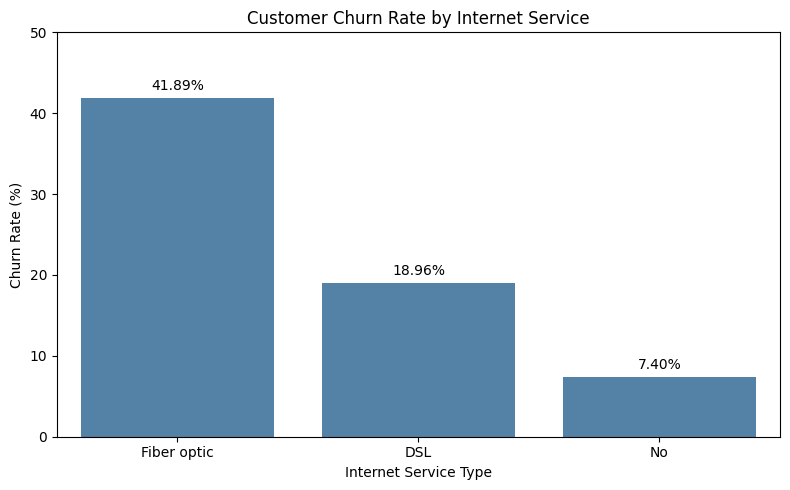

In [24]:
# Visualize churn rate by internet service type

plt.figure(figsize=(8, 5))

internet_churn_plot = internet_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

sns.barplot(
    data=internet_churn_plot,
    x="InternetService",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(internet_churn_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart reveals clear differences in customer churn rates across internet service categories.

Customers using **Fiber optic** have the highest churn rate at **41.89%**, followed by **DSL** customers at **18.96%**. Customers without internet service have the lowest churn rate at **7.40%**.

The churn rate among Fiber optic customers is substantially higher than that of the other groups. This pattern suggests that Fiber optic customers deserve further investigation to better understand the factors associated with their higher churn rate.

The company should examine whether contract types, monthly charges, tenure, and subscribed services help explain these differences. However, these results show an association between internet service category and churn and do not establish that the service type itself causes customers to leave.

### 12.7 Customer Churn by Payment Method

This analysis examines customer churn across different payment methods.

The objective is to compare customer counts and churn rates for each payment method to identify potential differences in customer retention.

Churn rates will be calculated as the percentage of customers using each payment method who have left the company. The results may help identify payment methods associated with higher churn rates, although they do not establish that payment method causes customer churn.

In [25]:
# Calculate churn rates by payment method

payment_churn = (
    df.groupby("PaymentMethod")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

payment_churn["Churn Rate (%)"] = (
    payment_churn["Churned_Customers"]
    / payment_churn["Customer_Count"] * 100
).round(2)

payment_churn = payment_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

display(payment_churn)

,PaymentMethod,Customer_Count,Churned_Customers,Churn Rate (%)
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24


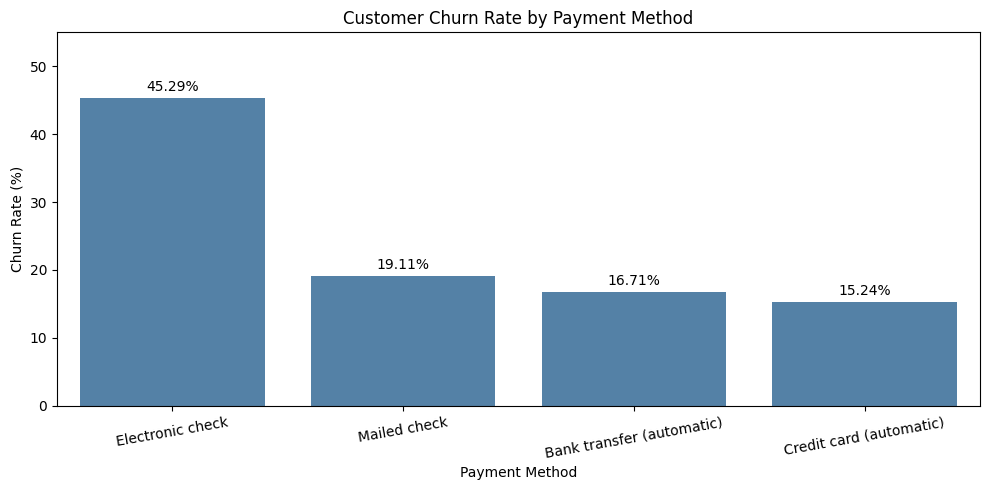

In [26]:
# Visualize churn rate by payment method

plt.figure(figsize=(10, 5))

payment_churn_plot = payment_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

sns.barplot(
    data=payment_churn_plot,
    x="PaymentMethod",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)
plt.xticks(rotation=10)

for i, value in enumerate(payment_churn_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart shows clear differences in customer churn rates across payment methods.

Customers who use **Electronic check** have the highest churn rate at **45.29%**. This is substantially higher than the rates for **Mailed check (19.11%)**, **Bank transfer (automatic) (16.71%)**, and **Credit card (automatic) (15.24%)**.

These findings indicate that customers using electronic checks are associated with a higher churn rate than customers using the other payment methods. The company should investigate whether this pattern is related to contract type, tenure, monthly charges, or other customer characteristics.

Although the results highlight an important pattern, they do not establish that the payment method itself causes customers to leave.

### 12.8 Customer Churn by Paperless Billing

This analysis examines customer churn across paperless billing categories.

The objective is to compare customer counts and churn rates between customers who use paperless billing and those who do not.

Churn rates will be calculated as the percentage of customers within each billing category who have left the company. This analysis may help identify differences in customer retention, although it does not establish that paperless billing causes customer churn.

In [27]:
# Calculate churn rates by paperless billing status

paperless_churn = (
    df.groupby("PaperlessBilling")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

paperless_churn["Churn Rate (%)"] = (
    paperless_churn["Churned_Customers"]
    / paperless_churn["Customer_Count"] * 100
).round(2)

display(paperless_churn)

,PaperlessBilling,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,2872,469,16.33
1,Yes,4171,1400,33.57


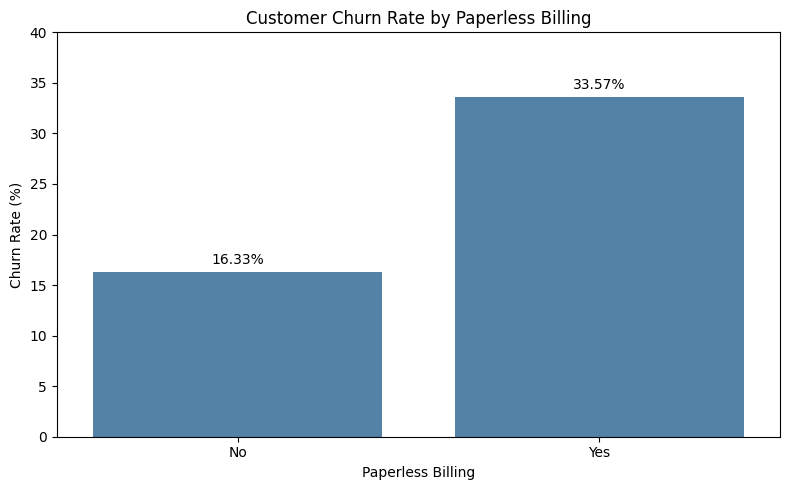

In [28]:
# Visualize churn rate by paperless billing status

plt.figure(figsize=(8, 5))

sns.barplot(
    data=paperless_churn,
    x="PaperlessBilling",
    y="Churn Rate (%)",
    order=["No", "Yes"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)

for i, value in enumerate(
    paperless_churn.set_index("PaperlessBilling")
    .loc[["No", "Yes"], "Churn Rate (%)"]
):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart reveals a noticeable difference in customer churn rates based on paperless billing status.

Customers who use **paperless billing** have a churn rate of **33.57%**, compared with **16.33%** among customers who do not use paperless billing.

The churn rate for paperless billing customers is approximately twice that of customers using traditional billing. This pattern suggests that paperless billing status may be associated with other customer characteristics that influence retention.

Further analysis should examine contract type, tenure, monthly charges, and payment method to determine whether these factors help explain the observed difference. However, this comparison does not establish that paperless billing causes customers to leave.

### 12.9 Customer Churn by Senior Citizen Status

This analysis examines customer churn based on senior citizen status.

The objective is to compare customer counts and churn rates between senior citizens and non-senior citizens to identify potential differences in customer retention.

Churn rates will be calculated as the percentage of customers within each group who have left the company. These results may reveal differences in churn patterns, although they do not establish that age category causes customer churn.

In [29]:
# Calculate churn rates by senior citizen status

senior_churn = (
    df.groupby("SeniorCitizen")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

senior_churn["Churn Rate (%)"] = (
    senior_churn["Churned_Customers"]
    / senior_churn["Customer_Count"] * 100
).round(2)

senior_churn["SeniorCitizen"] = senior_churn["SeniorCitizen"].map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

display(senior_churn)

,SeniorCitizen,Customer_Count,Churned_Customers,Churn Rate (%)
0,Non-Senior Citizen,5901,1393,23.61
1,Senior Citizen,1142,476,41.68


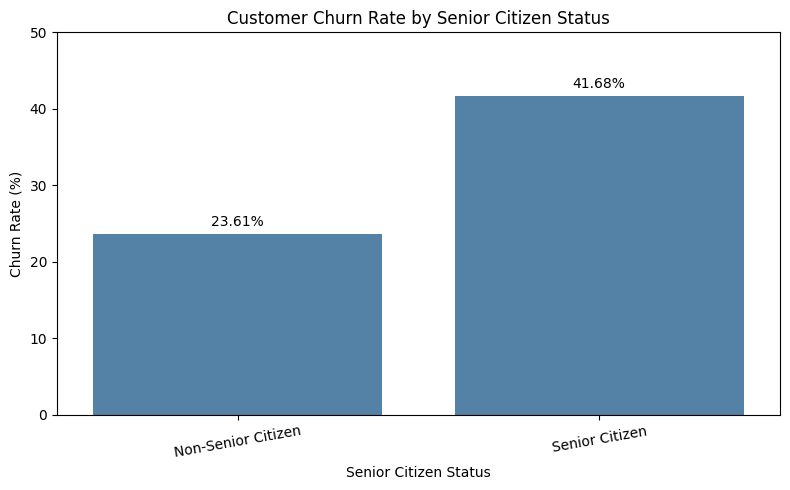

In [30]:
# Visualize churn rate by senior citizen status

plt.figure(figsize=(8, 5))

sns.barplot(
    data=senior_churn,
    x="SeniorCitizen",
    y="Churn Rate (%)",
    order=["Non-Senior Citizen", "Senior Citizen"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen Status")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.xticks(rotation=10)

for i, value in enumerate(
    senior_churn.set_index("SeniorCitizen")
    .loc[
        ["Non-Senior Citizen", "Senior Citizen"],
        "Churn Rate (%)"
    ]
):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart shows a clear difference in customer churn rates between senior citizens and non-senior citizens.

**Senior citizens** have a churn rate of **41.68%**, compared with **23.61%** for non-senior citizens. This indicates that the senior citizen group has a substantially higher proportion of customers who left the company.

This pattern suggests that senior citizens may represent a customer segment requiring further investigation into retention challenges. The company could examine whether contract types, tenure, subscribed services, and monthly charges are associated with the observed difference.

However, these results show an association between senior citizen status and churn and do not establish that age category causes customers to leave.

### 12.10 Customer Churn by Gender

This analysis examines customer churn across gender categories.

The objective is to compare customer counts and churn rates between male and female customers to identify any differences in customer retention.

Churn rates will be calculated as the percentage of customers within each gender category who have left the company. The results will help determine whether churn patterns differ between the two groups, although they do not establish that gender causes customer churn.

In [31]:
# Calculate churn rates by gender

gender_churn = (
    df.groupby("gender")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

gender_churn["Churn Rate (%)"] = (
    gender_churn["Churned_Customers"]
    / gender_churn["Customer_Count"] * 100
).round(2)

display(gender_churn)

,gender,Customer_Count,Churned_Customers,Churn Rate (%)
0,Female,3488,939,26.92
1,Male,3555,930,26.16


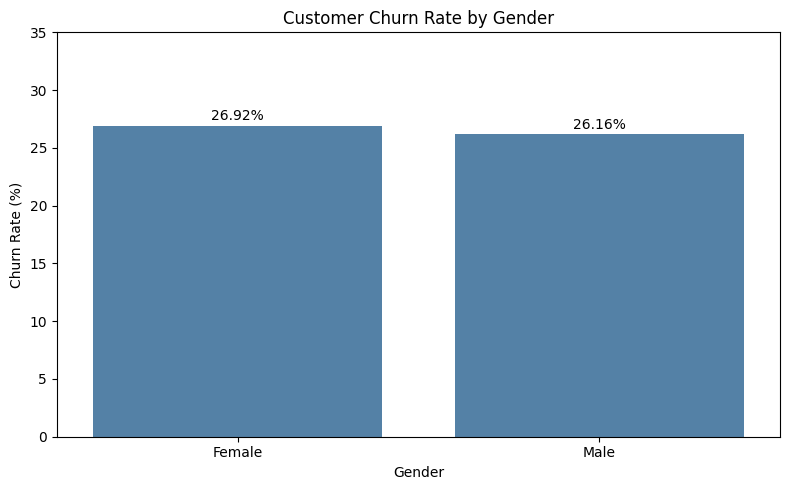

In [32]:
# Visualize churn rate by gender

plt.figure(figsize=(8, 5))

gender_churn_plot = gender_churn.copy()

sns.barplot(
    data=gender_churn_plot,
    x="gender",
    y="Churn Rate (%)",
    order=["Female", "Male"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 35)

for i, value in enumerate(
    gender_churn_plot.set_index("gender")
    .loc[["Female", "Male"], "Churn Rate (%)"]
):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart shows that customer churn rates are very similar between female and male customers.

Female customers have a churn rate of **26.92%**, while male customers have a rate of **26.16%**. The difference is only **0.76 percentage points**, indicating that churn rates are broadly similar across the two gender groups in this dataset.

Based on this descriptive comparison, gender does not appear to be a major differentiating factor in customer churn. Further analysis should focus on other characteristics, such as contract type, tenure, and monthly charges, which showed more substantial differences in earlier analyses.

These results describe the observed data and do not establish whether gender has any independent relationship with churn after accounting for other factors.

### 12.11 Customer Churn by Dependents Status

This analysis examines customer churn based on whether customers have dependents.

The objective is to compare customer counts and churn rates between customers with dependents and those without dependents to identify potential differences in customer retention.

Churn rates will be calculated as the percentage of customers within each group who have left the company. The results may help identify customer segments for further investigation, although they do not establish that dependent status causes customer churn.

In [33]:
# Calculate churn rates by dependents status

dependents_churn = (
    df.groupby("Dependents")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

dependents_churn["Churn Rate (%)"] = (
    dependents_churn["Churned_Customers"]
    / dependents_churn["Customer_Count"] * 100
).round(2)

display(dependents_churn)

,Dependents,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,4933,1543,31.28
1,Yes,2110,326,15.45


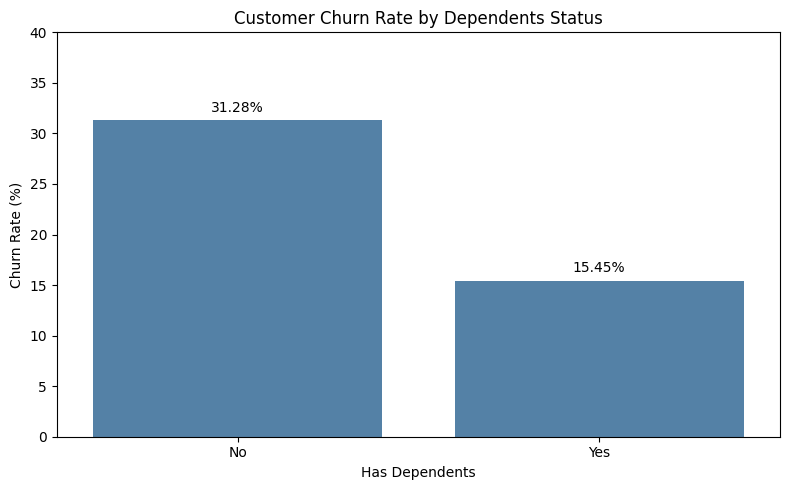

In [34]:
# Visualize churn rate by dependents status

plt.figure(figsize=(8, 5))

sns.barplot(
    data=dependents_churn,
    x="Dependents",
    y="Churn Rate (%)",
    order=["No", "Yes"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Dependents Status")
plt.xlabel("Has Dependents")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)

for i, value in enumerate(
    dependents_churn.set_index("Dependents")
    .loc[["No", "Yes"], "Churn Rate (%)"]
):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart shows a clear difference in customer churn rates based on dependents status.

Customers **without dependents** have a churn rate of **31.28%**, compared with **15.45%** among customers **with dependents**. The churn rate for customers without dependents is approximately twice that of customers with dependents.

This pattern suggests that customers without dependents may represent a segment requiring further investigation into retention challenges. The company could examine whether contract type, tenure, monthly charges, or other customer characteristics help explain the observed difference.

However, these results show an association between dependents status and churn and do not establish that having dependents directly affects whether a customer leaves.

### 12.12 Customer Churn by Partner Status

This analysis examines customer churn based on whether customers have a partner.

The objective is to compare customer counts and churn rates between customers with a partner and those without a partner to identify potential differences in customer retention.

Churn rates will be calculated as the percentage of customers within each group who have left the company. The results may help identify customer segments for further investigation, although they do not establish that partner status causes customer churn.

In [35]:
# Calculate churn rates by partner status

partner_churn = (
    df.groupby("Partner")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

partner_churn["Churn Rate (%)"] = (
    partner_churn["Churned_Customers"]
    / partner_churn["Customer_Count"] * 100
).round(2)

display(partner_churn)

,Partner,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,3641,1200,32.96
1,Yes,3402,669,19.66


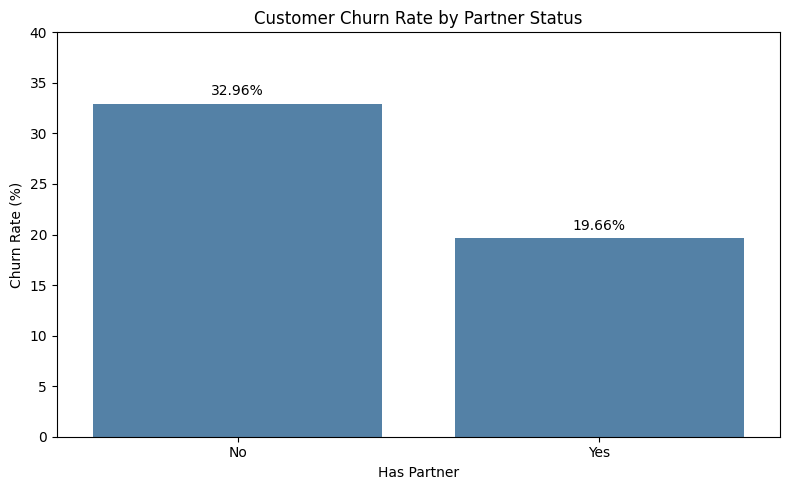

In [36]:
# Visualize churn rate by partner status

plt.figure(figsize=(8, 5))

sns.barplot(
    data=partner_churn,
    x="Partner",
    y="Churn Rate (%)",
    order=["No", "Yes"],
    color="steelblue"
)

plt.title("Customer Churn Rate by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)

for i, value in enumerate(
    partner_churn.set_index("Partner")
    .loc[["No", "Yes"], "Churn Rate (%)"]
):
    plt.text(i, value + 0.8, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart shows a clear difference in customer churn rates based on partner status.

Customers **without a partner** have a churn rate of **32.96%**, compared with **19.66%** among customers **with a partner**. This indicates that the proportion of customers who churned is higher among those without a partner in this dataset.

This pattern suggests that partner status may be associated with other customer characteristics related to retention. Further analysis could examine contract type, tenure, monthly charges, and dependents status to better understand the observed difference.

However, these results show an association between partner status and churn and do not establish that partner status itself causes customers to leave.

### 12.13 Customer Churn by Online Security

This analysis examines customer churn based on whether customers subscribe to the Online Security service.

The objective is to compare customer counts and churn rates between customers who have Online Security and those who do not. Customers without internet service are treated as a separate category.

Churn rates will be calculated as the percentage of customers within each category who have left the company. This comparison may help identify service-related patterns associated with customer retention, although it does not establish that Online Security directly affects churn.

In [37]:
# Calculate churn rates by online security status

security_churn = (
    df.groupby("OnlineSecurity")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

security_churn["Churn Rate (%)"] = (
    security_churn["Churned_Customers"]
    / security_churn["Customer_Count"] * 100
).round(2)

display(security_churn)

,OnlineSecurity,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,3498,1461,41.77
1,No internet service,1526,113,7.40
2,Yes,2019,295,14.61


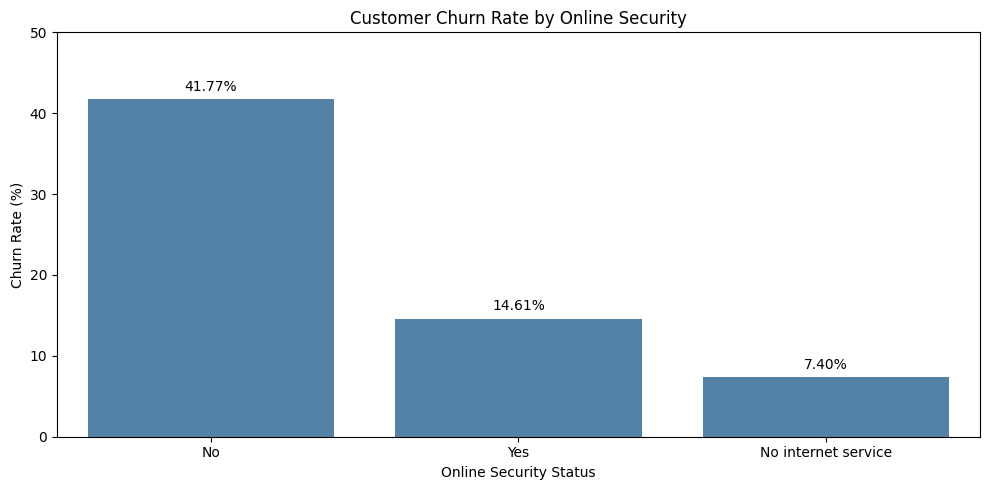

In [38]:
# Visualize churn rate by online security status

plt.figure(figsize=(10, 5))

security_churn_plot = security_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

sns.barplot(
    data=security_churn_plot,
    x="OnlineSecurity",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Online Security")
plt.xlabel("Online Security Status")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(security_churn_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart reveals substantial differences in customer churn rates across Online Security categories.

Customers **without Online Security** have the highest churn rate at **41.77%**. In comparison, customers **with Online Security** have a churn rate of **14.61%**, while customers **without internet service** have the lowest rate at **7.40%**.

This pattern indicates that customers without Online Security are associated with a considerably higher churn rate than customers who subscribe to the service. The company should investigate whether this difference is related to internet service type, contract type, tenure, or monthly charges.

However, these results show an association between Online Security status and churn and do not establish that subscribing to Online Security directly reduces customer churn.

### 12.14 Customer Churn by Tech Support

This analysis examines customer churn based on whether customers subscribe to the Tech Support service.

The objective is to compare customer counts and churn rates among customers with Tech Support, customers without Tech Support, and customers without internet service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help identify service-related patterns associated with customer retention, although they do not establish that Tech Support directly affects churn.

In [39]:
# Calculate churn rates by tech support status

techsupport_churn = (
    df.groupby("TechSupport")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

techsupport_churn["Churn Rate (%)"] = (
    techsupport_churn["Churned_Customers"]
    / techsupport_churn["Customer_Count"] * 100
).round(2)

display(techsupport_churn)

,TechSupport,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,3473,1446,41.64
1,No internet service,1526,113,7.40
2,Yes,2044,310,15.17


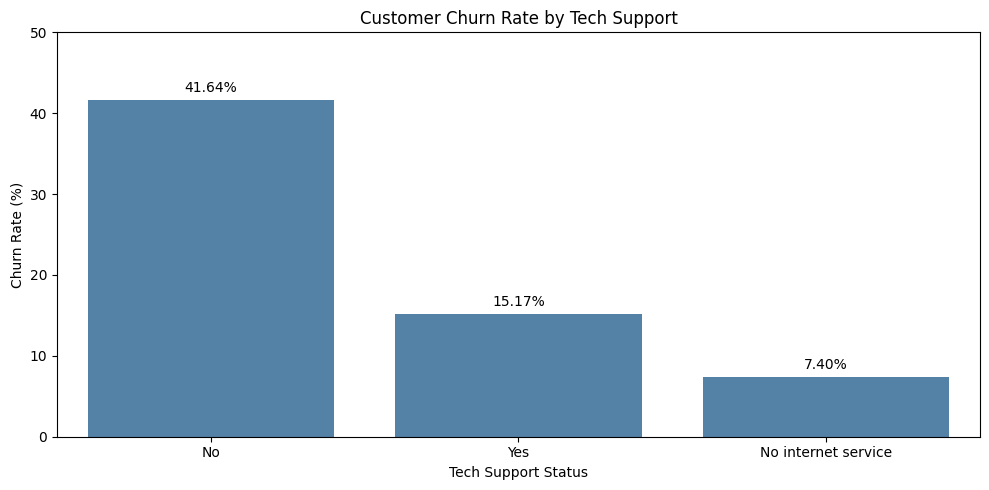

In [40]:
# Visualize churn rate by tech support status

plt.figure(figsize=(10, 5))

techsupport_churn_plot = techsupport_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

sns.barplot(
    data=techsupport_churn_plot,
    x="TechSupport",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Tech Support")
plt.xlabel("Tech Support Status")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(
    techsupport_churn_plot["Churn Rate (%)"]
):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

#### Bar Chart Findings

The bar chart reveals substantial differences in customer churn rates across Tech Support categories.

Customers **without Tech Support** have the highest churn rate at **41.64%**. In comparison, customers **with Tech Support** have a churn rate of **15.17%**, while customers **without internet service** have the lowest rate at **7.40%**.

This pattern indicates that customers without Tech Support are associated with a considerably higher churn rate than customers who subscribe to the service. The company should investigate whether this difference is related to contract type, tenure, monthly charges, or other service characteristics.

However, these results show an association between Tech Support status and churn and do not establish that subscribing to Tech Support directly reduces customer churn.

### 12.15 Customer Churn by Online Backup

This analysis examines customer churn based on whether customers subscribe to the Online Backup service.

The objective is to compare customer counts and churn rates among customers with Online Backup, customers without Online Backup, and customers without internet service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help identify service-related patterns associated with customer retention, although they do not establish that Online Backup directly affects churn.

In [41]:
# Calculate churn rates by online backup status

backup_churn = (
    df.groupby("OnlineBackup")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

backup_churn["Churn Rate (%)"] = (
    backup_churn["Churned_Customers"]
    / backup_churn["Customer_Count"] * 100
).round(2)

display(backup_churn)

,OnlineBackup,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,3088,1233,39.93
1,No internet service,1526,113,7.40
2,Yes,2429,523,21.53


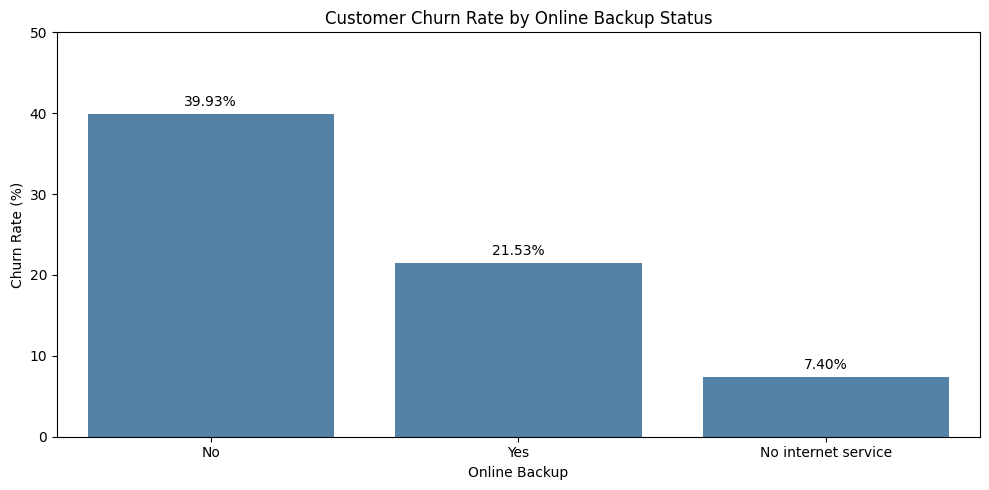

In [42]:
# Visualize churn rates by online backup status

backup_churn_plot = backup_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=backup_churn_plot,
    x="OnlineBackup",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Online Backup Status")
plt.xlabel("Online Backup")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(backup_churn_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

**Bar Chart Findings**

The analysis shows that customers without Online Backup have the highest churn rate at **39.93%**, compared with **21.53%** for customers who subscribe to Online Backup. Customers without internet service have the lowest churn rate at **7.40%**.

These results indicate that not having Online Backup is associated with a higher churn rate among customers. However, this relationship does not establish that Online Backup directly reduces churn, as other factors, such as contract type and monthly charges, may also be relevant.

### 12.16 Customer Churn by Device Protection

This analysis examines customer churn based on whether customers subscribe to the Device Protection service.

The objective is to compare customer counts and churn rates among customers with Device Protection, customers without Device Protection, and customers without internet service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help identify service-related patterns associated with customer retention, although they do not establish that Device Protection directly affects churn.

In [43]:
# Calculate churn rates by device protection status

device_protection_churn = (
    df.groupby("DeviceProtection")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

device_protection_churn["Churn Rate (%)"] = (
    device_protection_churn["Churned_Customers"]
    / device_protection_churn["Customer_Count"] * 100
).round(2)

display(device_protection_churn)

,DeviceProtection,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,3095,1211,39.13
1,No internet service,1526,113,7.40
2,Yes,2422,545,22.50


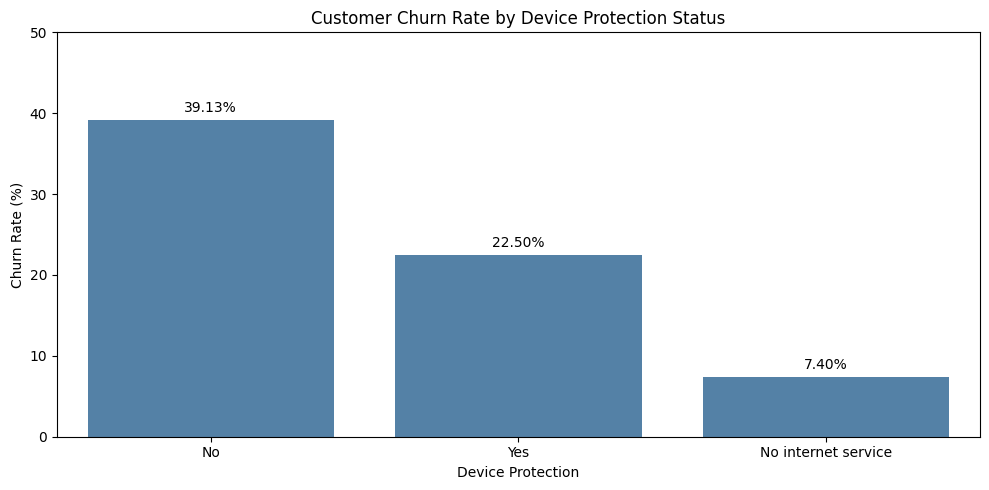

In [44]:
# Visualize churn rates by device protection status

device_protection_plot = device_protection_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=device_protection_plot,
    x="DeviceProtection",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Device Protection Status")
plt.xlabel("Device Protection")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(device_protection_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

**Bar Chart Findings**

The analysis shows that customers without Device Protection have the highest churn rate at **39.13%**, compared with **22.50%** for customers who subscribe to Device Protection. Customers without internet service have the lowest churn rate at **7.40%**.

These results indicate that not having Device Protection is associated with a higher churn rate. However, this association does not prove that Device Protection directly reduces churn, as other factors, including contract type, tenure, and monthly charges, may also influence customer retention.

### 12.17 Customer Churn by Streaming TV

This analysis examines customer churn based on whether customers subscribe to the Streaming TV service.

The objective is to compare customer counts and churn rates among customers with Streaming TV, customers without Streaming TV, and customers without internet service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help identify service-related patterns associated with customer retention, although they do not establish that Streaming TV directly affects churn.

In [45]:
# Calculate churn rates by Streaming TV status

streaming_tv_churn = (
    df.groupby("StreamingTV")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

streaming_tv_churn["Churn Rate (%)"] = (
    streaming_tv_churn["Churned_Customers"]
    / streaming_tv_churn["Customer_Count"] * 100
).round(2)

display(streaming_tv_churn)

,StreamingTV,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,2810,942,33.52
1,No internet service,1526,113,7.40
2,Yes,2707,814,30.07


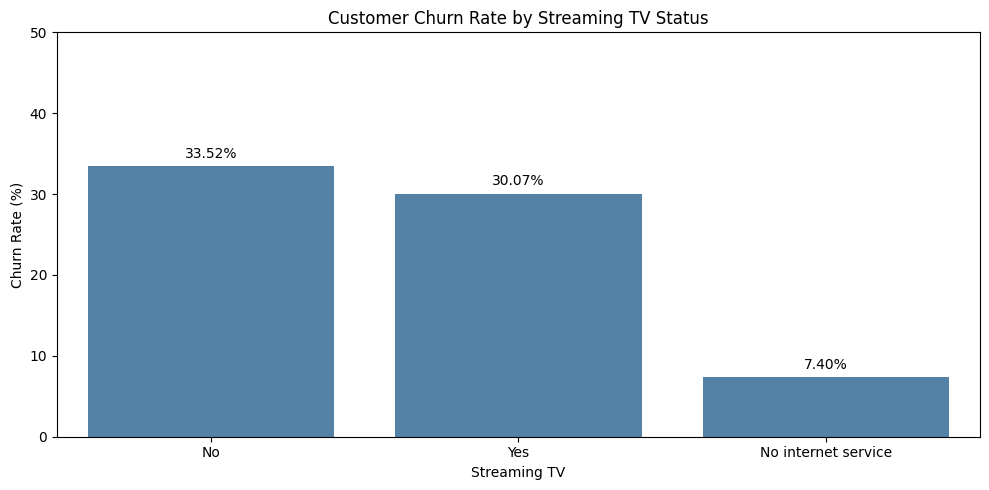

In [46]:
# Visualize churn rates by Streaming TV status

streaming_tv_plot = streaming_tv_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=streaming_tv_plot,
    x="StreamingTV",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Streaming TV Status")
plt.xlabel("Streaming TV")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(streaming_tv_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

**Bar Chart Findings**

The analysis shows that customers without Streaming TV have a churn rate of **33.52%**, while customers who subscribe to Streaming TV have a similar rate of **30.07%**. Customers without internet service have the lowest churn rate at **7.40%**.

The difference between customers with and without Streaming TV is relatively small compared with the differences observed for some other services. This suggests that Streaming TV subscription status alone may not be a strong indicator of churn, and other factors should be considered when examining customer retention.

### 12.18 Customer Churn by Streaming Movies

This analysis examines customer churn based on whether customers subscribe to the Streaming Movies service.

The objective is to compare customer counts and churn rates among customers with Streaming Movies, customers without Streaming Movies, and customers without internet service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help identify service-related patterns associated with customer retention, although they do not establish that Streaming Movies directly affects churn.

In [47]:
# Calculate churn rates by Streaming Movies status

streaming_movies_churn = (
    df.groupby("StreamingMovies")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

streaming_movies_churn["Churn Rate (%)"] = (
    streaming_movies_churn["Churned_Customers"]
    / streaming_movies_churn["Customer_Count"] * 100
).round(2)

display(streaming_movies_churn)

,StreamingMovies,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,2785,938,33.68
1,No internet service,1526,113,7.40
2,Yes,2732,818,29.94


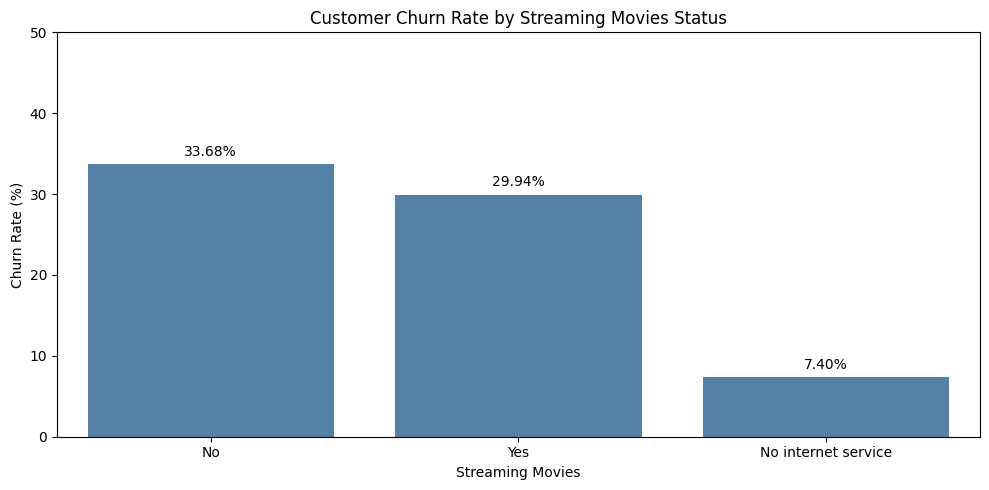

In [48]:
# Visualize churn rates by Streaming Movies status

streaming_movies_plot = streaming_movies_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=streaming_movies_plot,
    x="StreamingMovies",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Streaming Movies Status")
plt.xlabel("Streaming Movies")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(streaming_movies_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

**Bar Chart Findings**

The analysis shows that customers without Streaming Movies have the highest churn rate at **33.68%**, compared with **29.94%** for customers who subscribe to Streaming Movies. Customers without internet service have the lowest churn rate at **7.40%**.

The difference between customers with and without Streaming Movies is relatively small. This suggests that Streaming Movies subscription status alone may not fully explain customer churn. Other factors, such as contract type, tenure, and monthly charges, should also be considered when examining customer retention.

### 12.19 Customer Churn by Multiple Lines

This analysis examines customer churn based on whether customers subscribe to the Multiple Lines telephone service.

The objective is to compare customer counts and churn rates among customers with Multiple Lines, customers without Multiple Lines, and customers without phone service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help identify patterns associated with telephone service options and customer retention, without assuming a direct causal relationship.

In [49]:
# Calculate churn rates by multiple lines status

multiple_lines_churn = (
    df.groupby("MultipleLines")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

multiple_lines_churn["Churn Rate (%)"] = (
    multiple_lines_churn["Churned_Customers"]
    / multiple_lines_churn["Customer_Count"] * 100
).round(2)

display(multiple_lines_churn)

,MultipleLines,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,3390,849,25.04
1,No phone service,682,170,24.93
2,Yes,2971,850,28.61


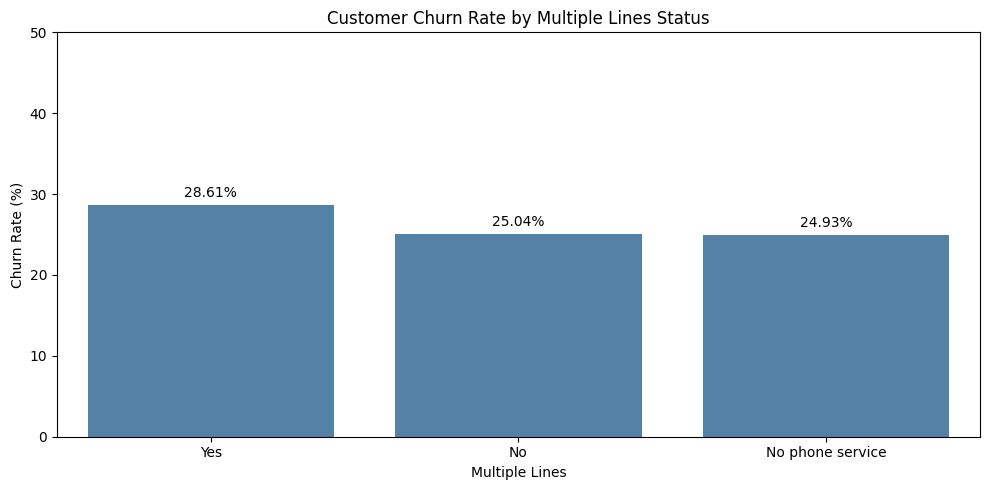

In [50]:
# Visualize churn rates by multiple lines status

multiple_lines_plot = multiple_lines_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=multiple_lines_plot,
    x="MultipleLines",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Multiple Lines Status")
plt.xlabel("Multiple Lines")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for i, value in enumerate(multiple_lines_plot["Churn Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

**Bar Chart Findings**

The analysis shows that customers with Multiple Lines have a churn rate of **28.61%**, compared with **25.04%** for customers without Multiple Lines. Customers without phone service have a similar churn rate of **24.93%**.

The differences between these groups are relatively small. This suggests that Multiple Lines status alone may provide limited insight into customer churn compared with factors such as contract type, customer tenure, and monthly charges.

### 12.20 Customer Churn by Phone Service

This analysis examines customer churn based on whether customers subscribe to the company's Phone Service.

The objective is to compare customer counts and churn rates between customers with Phone Service and customers without Phone Service.

Churn rates will be calculated as the percentage of customers within each category who have left the company. The results may help determine whether Phone Service status is associated with differences in customer retention, without assuming a direct causal relationship.

In [51]:
# Calculate churn rates by phone service status

phone_service_churn = (
    df.groupby("PhoneService")
    .agg(
        Customer_Count=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

phone_service_churn["Churn Rate (%)"] = (
    phone_service_churn["Churned_Customers"]
    / phone_service_churn["Customer_Count"] * 100
).round(2)

display(phone_service_churn)

,PhoneService,Customer_Count,Churned_Customers,Churn Rate (%)
0,No,682,170,24.93
1,Yes,6361,1699,26.71


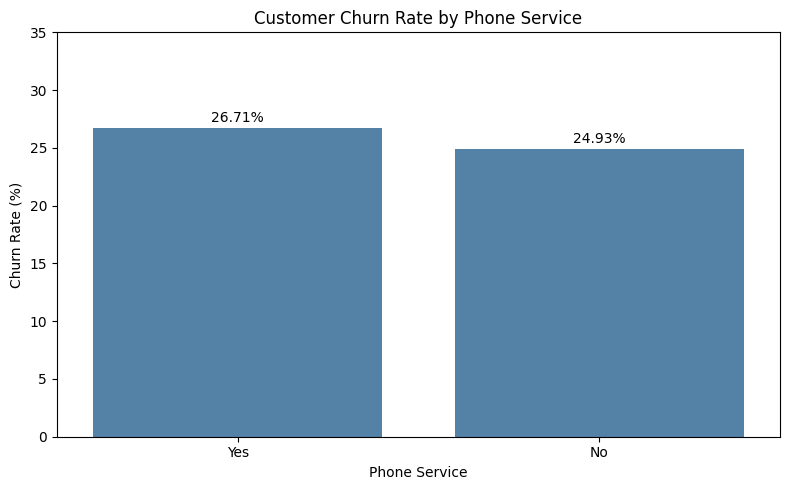

In [52]:
# Visualize churn rates by phone service status

phone_service_plot = phone_service_churn.sort_values(
    "Churn Rate (%)",
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=phone_service_plot,
    x="PhoneService",
    y="Churn Rate (%)",
    color="steelblue"
)

plt.title("Customer Churn Rate by Phone Service")
plt.xlabel("Phone Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 35)

for i, value in enumerate(phone_service_plot["Churn Rate (%)"]):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

**Bar Chart Findings**

The analysis shows that customers with Phone Service have a churn rate of **26.71%**, compared with **24.93%** for customers without Phone Service. The difference is relatively small, at approximately **1.78 percentage points**.

This suggests that Phone Service status alone has a limited association with customer churn in this dataset. Other factors, such as contract type, tenure, and monthly charges, show more substantial differences in churn rates and deserve greater attention in retention analysis.

## 13. Key Findings and Business Recommendations

This section summarizes the main findings from the exploratory data analysis (EDA) and translates them into practical recommendations to help the company better understand customer churn and identify opportunities to improve customer retention.

### 13.1 Key Findings

1. **Overall Churn:** Approximately 26.54% of customers have left the company, indicating a significant customer retention challenge.

2. **Contract Type:** Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

3. **Customer Tenure:** Customers with 0–12 months of tenure have the highest churn rate at 47.44%. Churn rates decline across the longer-tenure groups.

4. **Monthly Charges:** Customers in the high monthly-charge group have a churn rate of 35.36%, compared with 10.89% in the low-charge group.

5. **Internet Service:** Fiber optic customers have a churn rate of 41.89%, higher than DSL customers at 18.96%.

6. **Payment Method:** Customers using electronic checks have the highest churn rate among payment-method groups, at 45.29%.

7. **Additional Services:** Customers without Online Security, Tech Support, Online Backup, or Device Protection generally have higher churn rates than customers who subscribe to these services.

8. **Customer Demographics:** Senior citizens have a churn rate of 41.68%, compared with 23.61% for non-senior customers. Customers without partners or dependents also show higher churn rates in this dataset.

These findings describe associations in the dataset and do not establish that any individual factor directly causes customer churn.

### 13.2 Business Recommendations

Based on the exploratory data analysis, the following actions could help the company investigate churn risks and improve customer retention.

1. **Strengthen Early-Customer Retention:** Develop an onboarding program for new customers during their first 12 months. Monitor early customer experiences and provide timely support to customers showing signs of dissatisfaction.

2. **Review Contract Strategies:** Investigate why month-to-month customers have substantially higher churn rates. Test optional incentives for longer-term contracts while maintaining flexibility for customers who prefer monthly plans.

3. **Evaluate Pricing and Value:** Review the relationship between monthly charges and churn. Assess whether customers perceive sufficient value for their current plans and consider targeted offers where appropriate.

4. **Investigate Fiber Optic Customer Experience:** Examine customer feedback, service quality, technical issues, and pricing among fiber optic customers to understand their higher observed churn rate.

5. **Review Electronic Check Payments:** Investigate whether customers using electronic checks experience different billing or payment-related issues. Evaluate whether offering convenient alternative payment methods could improve the customer experience.

6. **Promote Relevant Support Services:** Assess customer awareness, usage, and satisfaction with Online Security, Tech Support, Online Backup, and Device Protection. Test whether clearer service information or suitable bundles improve retention.

7. **Develop Targeted Retention Strategies:** Use customer characteristics and service information to identify groups that may benefit from additional support, while ensuring that retention offers are fair and relevant.

8. **Measure Results:** Track churn rate, retention rate, and customer feedback before and after implementing retention initiatives. Use controlled experiments where possible to evaluate whether each initiative produces measurable improvements.

These recommendations should be treated as hypotheses for further investigation and testing. The observed associations alone do not prove that any proposed action will reduce churn.

### 13.3 Limitations of the Analysis

Although this analysis provides useful insights into customer churn, several limitations should be considered when interpreting the results.

1. **Observational Data:** The analysis identifies associations between customer characteristics and churn but does not establish causal relationships.

2. **Limited Time Information:** The dataset does not provide a complete history of customer behavior over time, limiting the ability to identify when and why churn occurs.

3. **Customer Feedback:** The dataset does not directly explain customers' reasons for leaving, such as dissatisfaction with service quality, competitor offers, or billing experiences.

4. **Categorical Groupings:** Monthly charges were divided into low, medium, and high groups using selected thresholds. Different thresholds could produce different group-level results.

5. **Potentially Interacting Factors:** Factors such as contract type, tenure, monthly charges, and subscribed services may be related to one another. Individual churn-rate comparisons do not isolate the independent effect of each factor.

6. **No Predictive Model:** This stage focuses on exploratory data analysis and descriptive statistics. It does not yet evaluate a machine-learning model for predicting which customers are likely to churn.

Further analysis could address these limitations by examining additional customer information, investigating relationships between multiple variables, and evaluating predictive models using appropriate validation methods.

### 14. Conclusion

This project explored customer churn in a telecommunications dataset containing 7,043 customer records and 21 columns.

The exploratory data analysis identified several notable patterns. The overall churn rate was 26.54%, with particularly high churn rates among month-to-month customers, customers with shorter tenure, customers in the high monthly-charge group, and customers using electronic checks.

The analysis also highlighted differences in churn rates across internet services, additional services, and customer characteristics. These findings provide a useful starting point for investigating customer retention challenges and developing targeted strategies.

However, the results are descriptive and do not establish causation. Further investigation, customer feedback, and controlled testing would help determine which retention initiatives are most effective.

Overall, this project demonstrates the use of Python, Pandas, Matplotlib, and Seaborn to clean data, perform exploratory analysis, calculate churn rates, visualize patterns, and translate analytical findings into potential business actions.